# 04 - Idée 1 : l'identité de l'allocation

Question : certaines allocations sont-elles durablement « à suivre » ou « à contrer », et le modèle gagne-t-il à le savoir ?

En EDA, la part de jours gagnants allait de 38 % à 66 % selon l'allocation, et une règle « majorité historique de
l'allocation » faisait 51,1 % à elle seule. Reste à savoir si cette information s'ajoute à celle de la baseline.

Précautions contre la fuite : tout ce qui concerne une allocation est appris sur les dates d'entraînement du pli,
après la purge de 20 jours. Rien n'est calculé sur l'ensemble du train.

Référence : `logit_baseline` (51,73 % sur les dates récentes). Règle : gain moyen > 2 erreurs-types, sur les mêmes plis.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import sparse
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

import utils
from utils import compare

plt.rcParams.update({'figure.figsize': (9, 3.4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': .25, 'font.size': 10})
BLUE, GREY = '#2a6fdb', '#8a8f98'

X, y, Xt = utils.load_data()
ch, folds = utils.load_split()
recent = utils.recent_regime(X, ch)
is_recent = X.TS.map(recent).to_numpy()
up = (y > 0).to_numpy()
masks = [(X.TS.isin(f['train']).to_numpy(), X.TS.isin(f['val']).to_numpy()) for f in folds]

F = utils.baseline_features(X)
COLS = list(F.columns)
baseline = utils.journal_scores('logit_baseline')

ALLOCS = np.array(sorted(X.ALLOCATION.unique()))
def alloc_dummies(df):
    # matrice creuse lignes x 278 allocations, 1 dans la colonne de l'allocation de la ligne
    idx = pd.Series(np.arange(len(ALLOCS)), index=ALLOCS)[df.ALLOCATION].to_numpy()
    return sparse.csr_matrix((np.ones(len(df)), (np.arange(len(df)), idx)), shape=(len(df), len(ALLOCS)))

D = alloc_dummies(X)
print('baseline, dates récentes :', baseline.mean().round(4))

baseline, dates récentes : 0.5173


## 1. Le style d'une allocation tient-il dans le temps ?

En EDA, on avait comparé deux moitiés de dates tirées au hasard. Maintenant que la chronologie est connue, on peut
poser la question qui compte : le base rate d'une allocation dans l'ancien régime annonce-t-il celui du régime récent ?

206 allocations présentes dans les deux régimes
corrélation des base rates ancien / récent : 0.451


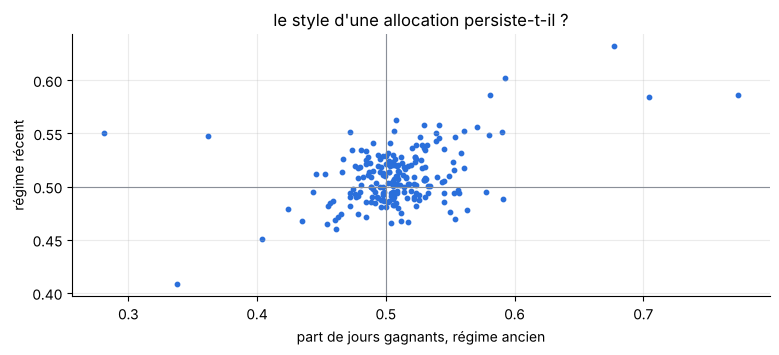

In [2]:
dev = X.TS.map(ch.set).eq('dev').to_numpy()
old_rate = pd.Series(up[dev & ~is_recent]).groupby(X.ALLOCATION[dev & ~is_recent].to_numpy()).agg(['mean', 'size'])
new_rate = pd.Series(up[dev & is_recent]).groupby(X.ALLOCATION[dev & is_recent].to_numpy()).agg(['mean', 'size'])
both = old_rate.join(new_rate, lsuffix='_ancien', rsuffix='_recent').query('size_ancien > 200 and size_recent > 200')
print(f"{len(both)} allocations présentes dans les deux régimes")
print(f"corrélation des base rates ancien / récent : {both.mean_ancien.corr(both.mean_recent):.3f}")

plt.scatter(both.mean_ancien, both.mean_recent, s=10, color=BLUE)
plt.axhline(.5, color=GREY, lw=.8); plt.axvline(.5, color=GREY, lw=.8)
plt.xlabel('part de jours gagnants, régime ancien'); plt.ylabel('régime récent')
plt.title("le style d'une allocation persiste-t-il ?")
plt.show()

Corrélation de 0,45 entre les deux régimes : une allocation qui gagnait souvent avant continue en général de gagner
souvent après. Le style persiste malgré le changement de régime, ce qui est la condition pour que l'idée tienne sur le
test, encore plus tardif. La persistance est imparfaite, d'où l'intérêt de régulariser fortement.

## 2. Trois façons d'encoder l'allocation

- **Target encoding** : on remplace l'allocation par sa part de jours gagnants sur le train du pli, rapprochée de la
  moyenne générale quand l'allocation a peu d'historique (shrinkage avec un poids `k` de pseudo-observations).
- **Effets fixes régularisés** : une indicatrice par allocation dans la logistique, avec une pénalité L2 qui tire les
  effets vers zéro. C'est l'équivalent statistique d'un shrinkage bayésien des base rates : une allocation n'obtient un
  effet que si son historique le justifie. Le paramètre `C` règle la force du rappel (petit `C` = rappel fort).
- **Effet « hier » propre à l'allocation** : une indicatrice par allocation multipliée par `ret1_z`, pour laisser
  chaque allocation avoir sa propre autocorrélation (certaines à suivre, d'autres à contrer).

Toutes les variantes testées sont affichées, y compris celles qui échouent. Plus on teste de variantes, plus le risque
de retenir un faux gagnant augmente : il faut pouvoir les compter.

In [3]:
def evaluate(build, C=1.0):
    # build(tr, va) -> (matrice train, matrice val) ; renvoie les accuracies par pli
    rec, allv = [], []
    for tr, va in masks:
        A_tr, A_va = build(tr, va)
        model = LogisticRegression(C=C, max_iter=3000).fit(A_tr, up[tr])
        hit = (model.predict_proba(A_va)[:, 1] > .5) == up[va]
        rec.append(hit[is_recent[va]].mean())
        allv.append(hit.mean())
    return np.array(rec), np.array(allv)

def scaled(tr, va):
    s = StandardScaler().fit(F.loc[tr, COLS])
    return s.transform(F.loc[tr, COLS]), s.transform(F.loc[va, COLS])

def with_target_encoding(k):
    def build(tr, va):
        a, b = scaled(tr, va)
        g = pd.DataFrame({'a': X.ALLOCATION.to_numpy()[tr], 'u': up[tr]}).groupby('a').u.agg(['sum', 'count'])
        prior = up[tr].mean()
        te = (g['sum'] + k * prior) / (g['count'] + k) - prior
        enc = X.ALLOCATION.map(te).fillna(0).to_numpy() * 10
        return np.c_[a, enc[tr]], np.c_[b, enc[va]]
    return build

def with_fixed_effects(extra):
    def build(tr, va):
        a, b = scaled(tr, va)
        return sparse.hstack([a, extra[tr]]).tocsr(), sparse.hstack([b, extra[va]]).tocsr()
    return build

DR = D.multiply(F.ret1_z.to_numpy()[:, None]).tocsr()   # allocation x ret1_z

variants = {
    'target encoding k=200':        (with_target_encoding(200), 1.0),
    'target encoding k=1000':       (with_target_encoding(1000), 1.0),
    'effets fixes C=1':             (with_fixed_effects(D), 1.0),
    'effets fixes C=0.1':           (with_fixed_effects(D), 0.1),
    'effets fixes C=0.01':          (with_fixed_effects(D), 0.01),
    'effets fixes C=0.003':         (with_fixed_effects(D), 0.003),
    'effets fixes C=0.001':         (with_fixed_effects(D), 0.001),
    'effet hier par allocation':    (with_fixed_effects(sparse.hstack([D, DR]).tocsr()), 0.003),
}
results = {name: evaluate(build, C) for name, (build, C) in variants.items()}

rows = []
for name, (r, a) in results.items():
    c = compare(r, baseline)
    rows.append({'variante': name, 'récentes': r.mean(), 'toutes': a.mean(), 'gain': c['mean_diff'],
                 't': c['t'], 'plis gagnés': int((r > baseline).sum()), 'retenu': c['retenu']})
table = pd.DataFrame(rows).set_index('variante')
table.round(4)

,récentes,toutes,gain,t,plis gagnés,retenu
variante,,,,,,
target encoding k=200,0.5186,0.5241,0.0013,1.5462,5,False
target encoding k=1000,0.5187,0.5242,0.0013,1.6149,5,False
effets fixes C=1,0.5183,0.5238,0.0009,1.1290,5,False
effets fixes C=0.1,0.5185,0.5240,0.0012,1.5287,5,False
effets fixes C=0.01,0.5190,0.5244,0.0016,2.8300,7,True
effets fixes C=0.003,0.5189,0.5244,0.0016,5.6216,8,True
effets fixes C=0.001,0.5189,0.5240,0.0016,3.3530,7,True
effet hier par allocation,0.5188,0.5242,0.0014,3.0826,7,True


Lecture :
- Toutes les variantes qui encodent le **niveau** d'une allocation gagnent un peu, entre +0,1 et +0,2 point.
  Le gain grandit quand on régularise plus (`C` petit), puis se stabilise : on est sur un plateau entre `C` = 0,01 et 0,001,
  pas sur un pic trouvé par chance.
- L'**effet « hier » par allocation** n'apporte rien de plus. Presque toutes les allocations ont une autocorrélation positive,
  et les différences entre elles sont trop instables pour être apprises.
- Le gain est petit, mais il est **très régulier** d'un pli à l'autre (t élevé). C'est le profil d'un vrai effet, modeste.

On retient les **effets fixes avec `C` = 0,003**, au milieu du plateau.

In [4]:
best_name = 'effets fixes C=0.003'
best = results[best_name]
_ = utils.log_result('logit_alloc', *best, note='baseline + effets fixes allocation, L2 C=0.003')
print(best_name, {k: round(float(v), 4) if k != 'retenu' else v for k, v in compare(best[0], baseline).items()})

effets fixes C=0.003 {'mean_diff': 0.0016, 'se': 0.0003, 't': 5.6216, 'retenu': True}


## 3. Ce que le modèle a appris sur les allocations

On réentraîne sur tout le développement et on regarde les effets estimés. Un effet négatif signifie qu'à
situation égale (même rendement d'hier, même vol...), le modèle penche vers la baisse pour cette allocation.

{'count': 278.0, 'mean': 0.0, 'std': 0.052, 'min': -0.315, '25%': -0.022, '50%': -0.002, '75%': 0.024, 'max': 0.35}

les 5 effets les plus négatifs : {'ALLOCATION_156': -0.315, 'ALLOCATION_111': -0.28, 'ALLOCATION_86': -0.154, 'ALLOCATION_85': -0.123, 'ALLOCATION_185': -0.117}
les 5 effets les plus positifs : {'ALLOCATION_152': 0.35, 'ALLOCATION_31': 0.224, 'ALLOCATION_187': 0.175, 'ALLOCATION_168': 0.107, 'ALLOCATION_118': 0.101}


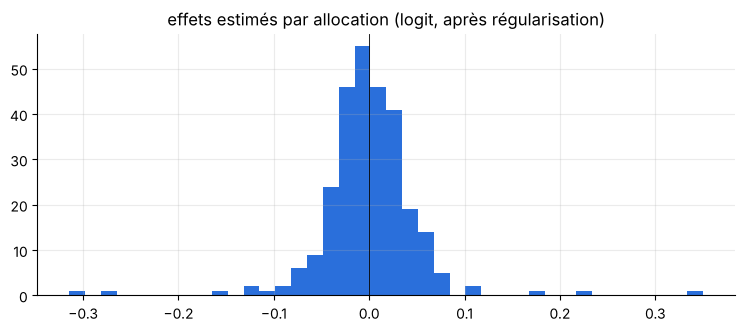

In [5]:
s = StandardScaler().fit(F.loc[dev, COLS])
model = LogisticRegression(C=0.003, max_iter=3000).fit(
    sparse.hstack([s.transform(F.loc[dev, COLS]), D[dev]]).tocsr(), up[dev])
effects = pd.Series(model.coef_[0][len(COLS):], index=ALLOCS)
print(effects.describe().round(3).to_dict())
print('\nles 5 effets les plus négatifs :', effects.nsmallest(5).round(3).to_dict())
print('les 5 effets les plus positifs :', effects.nlargest(5).round(3).to_dict())

plt.hist(effects, bins=40, color=BLUE)
plt.axvline(0, color='k', lw=.6)
plt.title('effets estimés par allocation (logit, après régularisation)')
plt.show()

La plupart des effets sont proches de zéro (la moitié entre -0,02 et +0,02) : la régularisation ne laisse un effet qu'aux
allocations dont l'historique le justifie. Quelques-unes ressortent nettement, jusqu'à -0,31 et +0,35. À titre de comparaison,
le coefficient de `ret1_z` est d'environ 0,11 : pour ces allocations, l'identité pèse deux à trois fois plus lourd que le
rendement de la veille. Ce sont celles que le modèle conseille de suivre, ou de contrer, quasiment quoi qu'il arrive.

## 4. Soumission

Même méthode qu'en étape c : on réentraîne sur tout le train et on prédit le test. Les 278 allocations du test sont
toutes présentes dans le train, il n'y a donc pas d'allocation inconnue.

In [6]:
assert set(Xt.ALLOCATION) <= set(ALLOCS)
s_all = StandardScaler().fit(F[COLS])
final = LogisticRegression(C=0.003, max_iter=3000).fit(sparse.hstack([s_all.transform(F[COLS]), D]).tocsr(), up)

Ft = utils.baseline_features(Xt)
At = sparse.hstack([s_all.transform(Ft[COLS]), alloc_dummies(Xt)]).tocsr()
pred_test = (final.predict_proba(At)[:, 1] > .5).astype(int)

sample = pd.read_csv(utils.find_data_dir() / 'sample_submission.csv', index_col='ROW_ID')
submission = pd.DataFrame({sample.columns[0]: pred_test}, index=Xt.index).loc[sample.index]
submission.index.name = 'ROW_ID'
Path('submissions').mkdir(exist_ok=True)
submission.to_csv('submissions/02_logit_alloc.csv')
print(submission.shape, '| part de 1 :', round(submission.iloc[:, 0].mean(), 3))

(31870, 1) | part de 1 : 0.572


## Bilan

| | dates récentes | toutes les dates |
|---|---|---|
| baseline logistique | 51,73 % | 52,19 % |
| baseline + effets fixes allocation (C = 0,003) | 51,89 % | 52,44 % |

- Gain de +0,16 point sur les dates récentes, **sur les 8 plis sur 8** (t = 5,6). L'idée est retenue.
- Le gain est petit en valeur absolue. Avec une incertitude d'environ ±0,5 point sur une soumission, il ne sera pas
  visible à coup sûr sur le score public. C'est pour ça qu'on décide sur la CV et pas sur le public.
- Ce qui n'a pas marché : laisser l'effet « hier » varier par allocation. Le comportement « à suivre / à contrer »
  passe par le niveau de l'allocation, pas par son autocorrélation.

Nouvelle référence pour la suite : `logit_alloc`.